# MIR–IF alignment quality control

**Input images must already be globally registered.** This notebook checks their alignment, illustrates plaque regions, and runs the `spatialmirif` QC implementation.

> Current `spatialmirif` QC can apply a **small translation-only** refinement. It does **not** perform the original rotation search or full initial registration.

## 1. Imports and paths

In [2]:
from pathlib import Path
import json
import math

import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from skimage import measure
from IPython.display import display, Image as NotebookImage
import spatialmirif as mi

from data_path import data_path_zarr_S1_N2, data_path_zarr_S1_N2_info, data_path_if_nrrd_S1_N2, data_path_full_slide_nrrd_S1_N2, output_path_S1_N2, data_path_mir_aligned_with_if, data_path_if_aligned, data_path_if_mask_aligned

# Original S1_N2 input paths.
mir_zarr = data_path_zarr_S1_N2
mir_info = data_path_zarr_S1_N2_info
if_nrrd = data_path_if_nrrd_S1_N2
bf_nrrd =  data_path_full_slide_nrrd_S1_N2
output_dir = output_path_S1_N2

SAMPLE_NAME = "S1_N2_qc_alignment"

# Keep the original S1_N2 pre-aligned input paths.
bf_path = data_path_full_slide_nrrd_S1_N2
mir_path = data_path_mir_aligned_with_if
if_path = data_path_if_aligned
mask_path = data_path_if_mask_aligned

output_dir = output_path_S1_N2/SAMPLE_NAME
output_dir.mkdir(parents=True, exist_ok=True)

figures_dir = output_dir / "qc_figures"
figures_dir.mkdir(parents=True, exist_ok=True)

PLAQUE_ZOOM_SELECTION = "random"
PLAQUE_ZOOM_SEED = 20
PLAQUE_ZOOM_COUNT = 12
PLAQUE_RADIUS_UM = 40.0

for label, path in {
    "Brightfield": bf_path,
    "Aligned MIR": mir_path,
    "Aligned IF": if_path,
    "Aligned IF mask": mask_path,
}.items():
    if not path.is_file():
        raise FileNotFoundError(f"{label} is missing: {path}")
    print(f"{label:17}: {path.name}")

print("QC figures:", figures_dir)


Brightfield      : PPS_Slide_1_BF_10x.nrrd
Aligned MIR      : S1_N2_MIR_1650_pymir_align.nrrd
Aligned IF       : S1_N2_IF_align.nrrd
Aligned IF mask  : S1_N2_IF_mask_pymir_align.nrrd
QC figures: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures


## 2. Read images and inspect geometry

In [3]:
# A scalar 2D image or single-slice 3D NRRD is expected.
images = {
    "BF": sitk.ReadImage(str(bf_path)),
    "MIR": sitk.ReadImage(str(mir_path)),
    "IF": sitk.ReadImage(str(if_path)),
    "Mask": sitk.ReadImage(str(mask_path)),
}

for name, image in images.items():
    print(
        f"{name:4}  dim={image.GetDimension()}  size={image.GetSize()}  "
        f"spacing={image.GetSpacing()}  origin={image.GetOrigin()}  "
        f"components={image.GetNumberOfComponentsPerPixel()}"
    )

def same_grid(a, b):
    return (
        a.GetDimension() == b.GetDimension()
        and a.GetSize() == b.GetSize()
        and np.allclose(a.GetSpacing(), b.GetSpacing(), atol=1e-7, rtol=0)
        and np.allclose(a.GetOrigin(), b.GetOrigin(), atol=1e-7, rtol=0)
        and np.allclose(a.GetDirection(), b.GetDirection(), atol=1e-7, rtol=0)
    )

# The IF image and its plaque mask must have identical physical geometry.
assert same_grid(images["IF"], images["Mask"]), "IF and mask geometry differ"
print("IF/mask geometry: matching")
if any(images[key].GetDimension() != images["MIR"].GetDimension() for key in ("BF", "IF", "Mask")):
    print("WARNING: current compact QC requires matching spatial dimensions across the input images.")


BF    dim=3  size=(8999, 3389, 1)  spacing=(0.005032999999999998, 0.005032999999999998, 0.01)  origin=(0.004529699999999082, 0.002768149999999636, 0.0)  components=1
MIR   dim=3  size=(1560, 2400, 1)  spacing=(0.004338395, 0.004338395, 0.01)  origin=(41.89689615939278, 2.3939999903086573, 0.0)  components=1
IF    dim=3  size=(2729, 1876, 1)  spacing=(0.0048632850160478915, 0.0048632850160478915, 0.010000000000000002)  origin=(43.018282118442215, 1.9342405832157503, 0.0)  components=1
Mask  dim=3  size=(2729, 1876, 1)  spacing=(0.0048632850160478915, 0.0048632850160478915, 0.010000000000000002)  origin=(43.018282118442215, 1.9342405832157503, 0.0)  components=1
IF/mask geometry: matching


## 3. Visualization helpers

In [4]:
# Display helpers never modify saved NRRDs.
def as_2d(image):
    if image.GetNumberOfComponentsPerPixel() != 1:
        raise ValueError("Expected a scalar NRRD; vector images are not supported by this QC module")
    array = np.squeeze(sitk.GetArrayFromImage(image))
    if array.ndim != 2:
        raise ValueError(f"Expected a 2D or single-slice image, received {array.shape}")
    return np.asarray(array)


def preview(array, limit=1400):
    # Use the same XY stride so large images display quickly.
    s = max(1, math.ceil(max(array.shape[:2]) / limit))
    return array[::s, ::s]


def contrast(array, p_low=1.0, p_high=99.5):
    # Robust display scaling; leaves source intensities unchanged.
    arr = np.nan_to_num(np.asarray(array, dtype=np.float32))
    valid = arr[np.isfinite(arr)]
    if not valid.size:
        return np.zeros_like(arr)
    low, high = np.percentile(valid, [p_low, p_high])
    if high <= low:
        return np.zeros_like(arr)
    return np.clip((arr - low) / (high - low), 0, 1)


def save_show(fig, filename):
    path = figures_dir / filename
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print("Saved:", path)
    return path


def resample_to_mir(image, nearest=False):
    # SimpleITK uses physical coordinates, not just array dimensions.
    reference = images["MIR"]
    if image.GetDimension() != reference.GetDimension():
        raise ValueError(
            "Input and MIR have different spatial dimensions. "
            "Export them on compatible physical grids before running QC."
        )
    return sitk.Resample(
        image, reference,
        sitk.Transform(reference.GetDimension(), sitk.sitkIdentity),
        sitk.sitkNearestNeighbor if nearest else sitk.sitkLinear,
        0.0, sitk.sitkFloat32,
    )


def rgb_overlay(mir_2d, if_2d, limit=1400):
    # Cyan = MIR; magenta = IF; light areas indicate spatial correspondence.
    a = contrast(preview(mir_2d, limit))
    b = contrast(preview(if_2d, limit))
    rgb = np.zeros((*a.shape, 3), dtype=np.float32)
    rgb[..., 0] = b
    rgb[..., 1] = a
    rgb[..., 2] = np.maximum(a, b) * 0.85
    return np.clip(rgb, 0, 1)


def show_mask_edges(ax, mask_2d, limit=1400):
    m = preview(mask_2d, limit) > 0
    if m.any() and (~m).any():
        ax.contour(m.astype(float), levels=[0.5], colors="lime", linewidths=0.7)


## 4. Inspect the four aligned input images

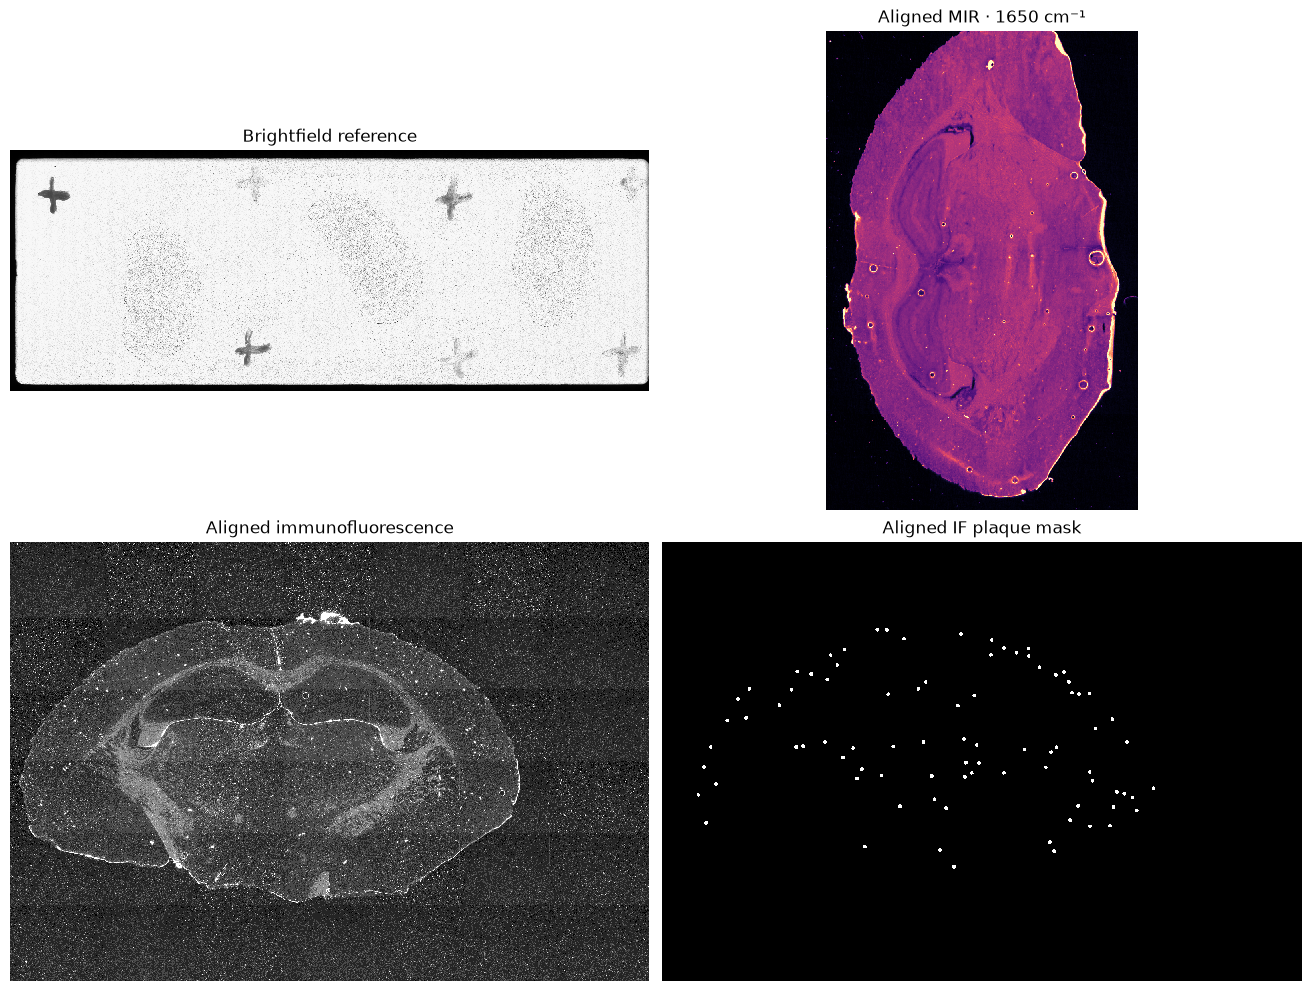

Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures\01_input_images.png


In [5]:
# Independent previews; input grids can have different shapes.
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
settings = [
    ("BF", "Brightfield reference", "gray"),
    ("MIR", "Aligned MIR · 1650 cm⁻¹", "magma"),
    ("IF", "Aligned immunofluorescence", "gray"),
    ("Mask", "Aligned IF plaque mask", "gray"),
]
for ax, (name, title, cmap) in zip(axes.flat, settings):
    a = preview(as_2d(images[name]))
    ax.imshow(a > 0 if name == "Mask" else contrast(a), cmap=cmap, interpolation="nearest")
    ax.set_title(title, fontsize=12)
    ax.axis("off")
preview_file = save_show(fig, "01_input_images.png")


## 5. Visual QC before refinement

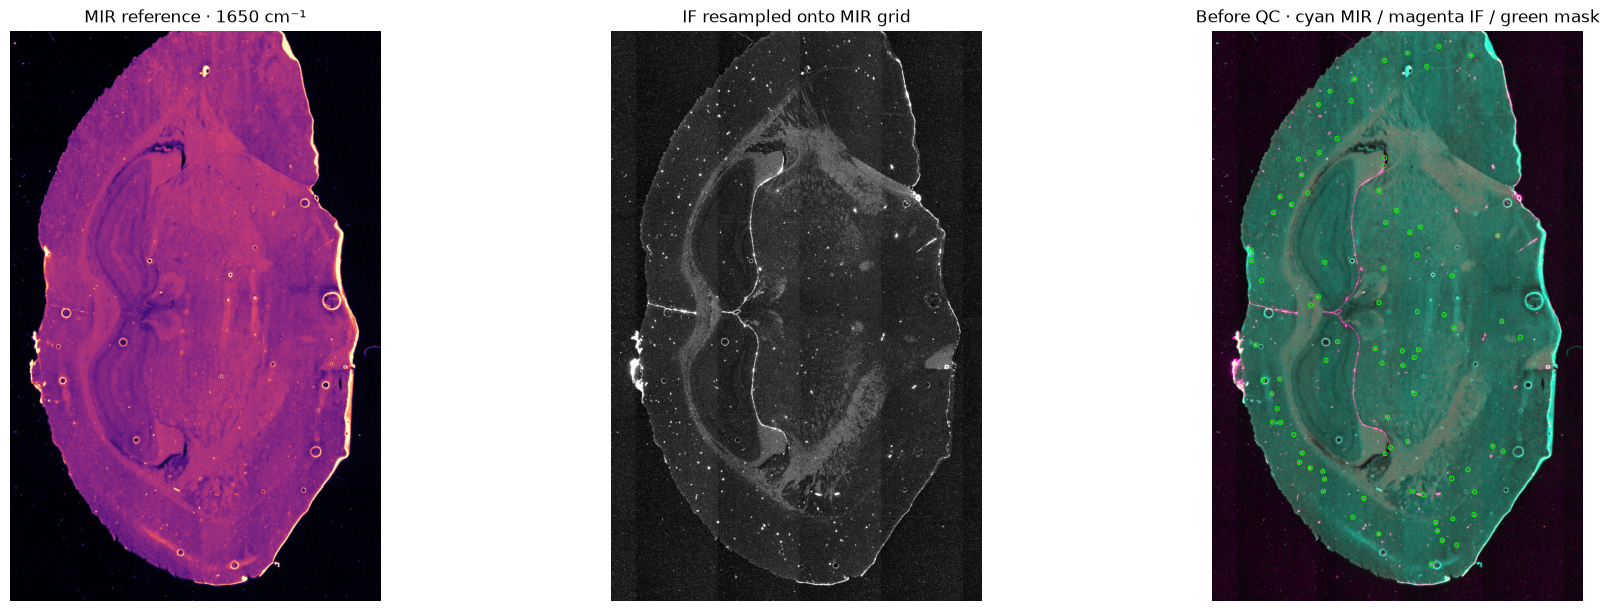

Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures\02_overlay_before_qc.png


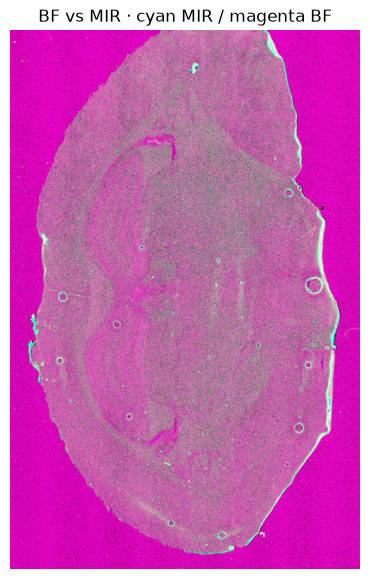

Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures\03_bf_vs_mir.png


In [6]:
# Resample IF and its mask to the MIR physical grid for overlays.
mir_array = as_2d(images["MIR"])
initial_if_on_mir = resample_to_mir(images["IF"])
initial_mask_on_mir = resample_to_mir(images["Mask"], nearest=True)
if_before = as_2d(initial_if_on_mir)
mask_before = as_2d(initial_mask_on_mir)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
axes[0].imshow(contrast(preview(mir_array)), cmap="magma")
axes[0].set_title("MIR reference · 1650 cm⁻¹")
axes[1].imshow(contrast(preview(if_before)), cmap="gray")
axes[1].set_title("IF resampled onto MIR grid")
axes[2].imshow(rgb_overlay(mir_array, if_before))
show_mask_edges(axes[2], mask_before)
axes[2].set_title("Before QC · cyan MIR / magenta IF / green mask")
for ax in axes:
    ax.axis("off")
before_file = save_show(fig, "02_overlay_before_qc.png")

# Optional BF-to-MIR structural overlay.
try:
    bf_on_mir = as_2d(resample_to_mir(images["BF"]))
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(rgb_overlay(mir_array, bf_on_mir))
    ax.set_title("BF vs MIR · cyan MIR / magenta BF")
    ax.axis("off")
    bf_file = save_show(fig, "03_bf_vs_mir.png")
except ValueError as exc:
    print("BF preview skipped:", exc)


## 6. Configure and run MIR–IF alignment QC

In [7]:
# Keep your original thresholds. Current spatialmirif QC only searches translation.
qc = mi.MIRIFAlignmentQC(
    brightfield=bf_path,
    mir_aligned=mir_path,
    if_aligned=if_path,
    mask_aligned=mask_path,
    output_dir=output_dir,
    sample_name=SAMPLE_NAME,
    plaque_radius_um=PLAQUE_RADIUS_UM,
    plaque_zoom_count=PLAQUE_ZOOM_COUNT,
    plaque_zoom_selection=PLAQUE_ZOOM_SELECTION,
    plaque_zoom_seed=PLAQUE_ZOOM_SEED,
    auto_refine=True,
    gross_max_shift_um=120.0,
    gross_max_rotation_deg=1.5,  # Accepted by API; not applied in compact QC.
    min_gradient_ncc=0.10,
    min_edge_dice=0.40,
    direct_max_shift_um=50.0,
    direct_max_rotation_deg=0.25,  # Accepted by API; no rotation search.
    min_score_gain=0.003,
    rotation_min_extra_gain=0.003,  # Reserved; no rotation search.
    post_max_residual_shift_um=15.0,
    post_max_rotation_deg=0.25,
    post_max_score_gain=0.003,
    save_figures=True,
    show_figures=False,  # QC figures are displayed in a later cell.
)

print("QC parameters:")
print(json.dumps(qc.GetParameters(), indent=2))

# Run once; the package saves its NRRD, PNG and JSON outputs.
summary = qc.Run()
print("QC status:", summary.get("status", summary.get("pipeline_status", "Unknown")))


QC parameters:
{
  "plaque_radius_um": 40.0,
  "plaque_zoom_count": 12,
  "plaque_zoom_selection": "random",
  "plaque_zoom_seed": 20,
  "auto_refine": true,
  "save_figures": true,
  "show_figures": false,
  "gross_max_shift_um": 120.0,
  "gross_max_rotation_deg": 1.5,
  "min_gradient_ncc": 0.1,
  "min_edge_dice": 0.4,
  "direct_max_shift_um": 50.0,
  "direct_max_rotation_deg": 0.25,
  "min_score_gain": 0.003,
  "rotation_min_extra_gain": 0.003,
  "post_max_residual_shift_um": 15.0,
  "post_max_rotation_deg": 0.25,
  "post_max_score_gain": 0.003
}


c:\Users\arsla\anaconda3\envs\spatialmirif-dev\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


QC status: REVIEW


## 7. Review QC metrics and applied shift

QC status                : REVIEW
Translation applied      : False
Applied translation (µm) : dx=0.00, dy=0.00
Rotation search          : not implemented in this compact QC
Initial MIR–IF metrics   : {'gradient_ncc': 0.23579071601984022, 'edge_dice': 0.2616883800523548, 'overlap_fraction': 0.9978741987179487}
Final MIR–IF metrics     : {'gradient_ncc': 0.23579071601984022, 'edge_dice': 0.2616883800523548, 'overlap_fraction': 0.9978741987179487}
Grid checks              : {'brightfield': False, 'if_aligned': False, 'mask_aligned': False}


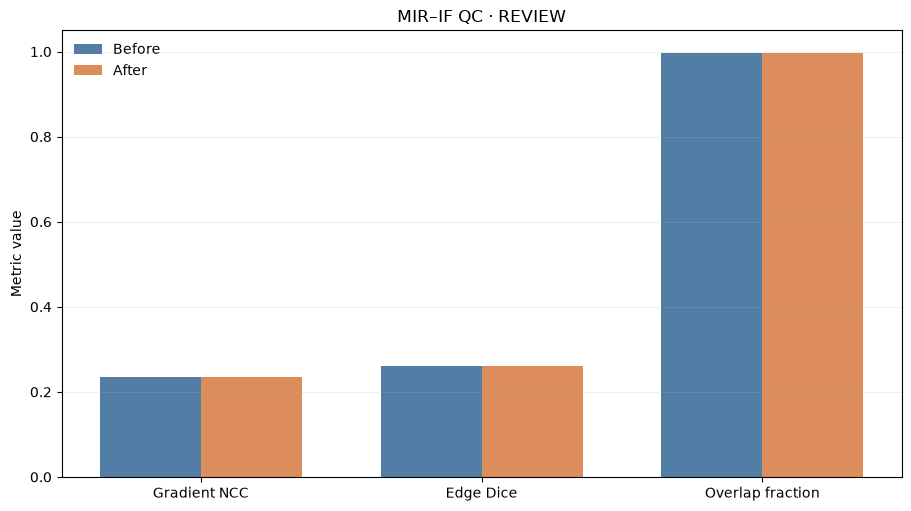

Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures\04_qc_metrics.png


In [8]:
# The compact QC summary has different keys from the original pymirimaging QC.
status = summary.get("status", summary.get("pipeline_status", "Unknown"))
applied = summary.get("automatic_translation_applied", False)
shift_mm = np.asarray(summary.get("translation_mm_xy", (0.0, 0.0)), dtype=float)
shift_um = shift_mm * 1000.0
before_metrics = summary.get("original_mir_if", {})
after_metrics = summary.get("final_mir_if", {})

print("QC status                :", status)
print("Translation applied      :", applied)
print(f"Applied translation (µm) : dx={shift_um[0]:.2f}, dy={shift_um[1]:.2f}")
print("Rotation search          : not implemented in this compact QC")
print("Initial MIR–IF metrics   :", before_metrics)
print("Final MIR–IF metrics     :", after_metrics)
print("Grid checks              :", summary.get("same_grid_as_mir"))

# Compare structural metrics before and after QC.
metric_keys = ("gradient_ncc", "edge_dice", "overlap_fraction")
labels = ("Gradient NCC", "Edge Dice", "Overlap fraction")
initial_values = [before_metrics.get(k, np.nan) for k in metric_keys]
final_values = [after_metrics.get(k, np.nan) for k in metric_keys]

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.bar(x - 0.18, initial_values, width=0.36, label="Before", color="#527da5")
ax.bar(x + 0.18, final_values, width=0.36, label="After", color="#dd8d5c")
ax.set_xticks(x, labels)
if all(np.isfinite(v) for v in initial_values + final_values) and min(initial_values + final_values) >= 0 and max(initial_values + final_values) <= 1:
    ax.set_ylim(0, 1.05)
ax.set_ylabel("Metric value")
ax.set_title(f"MIR–IF QC · {status}")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
metrics_file = save_show(fig, "04_qc_metrics.png")


## 8. Compare images before and after QC

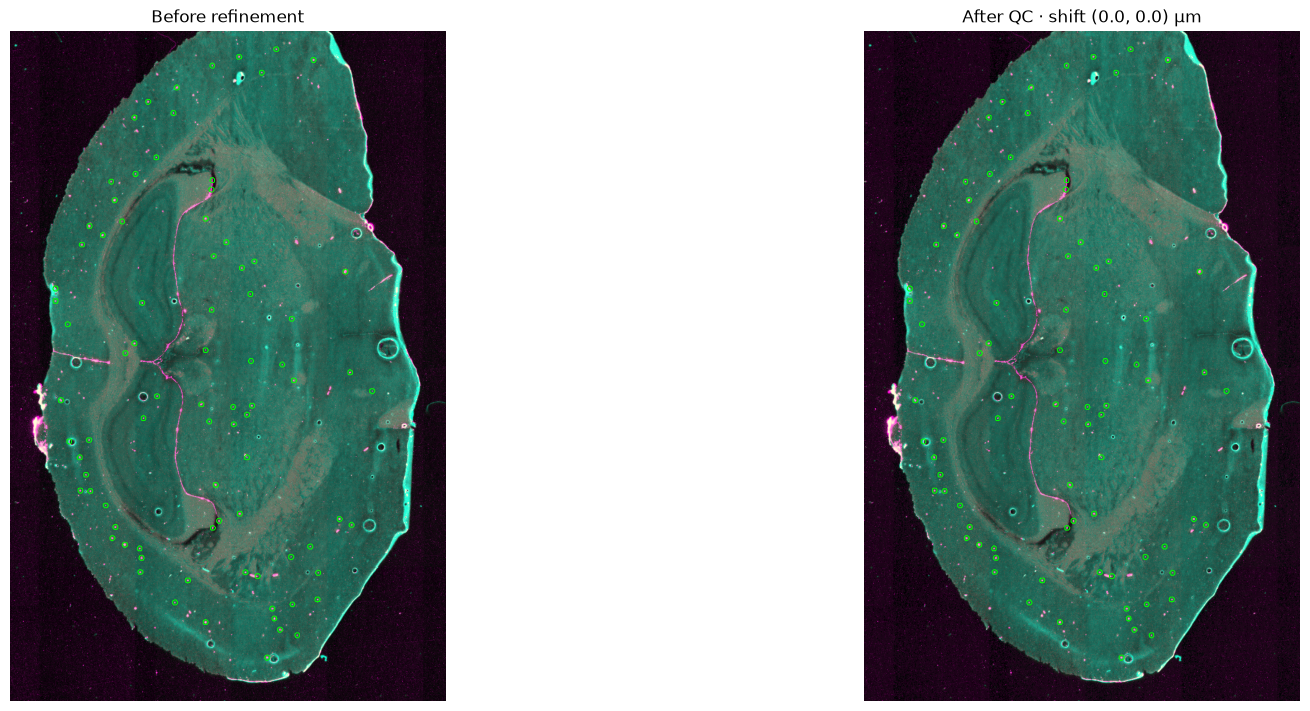

Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures\05_before_after_qc.png


In [9]:
# Get final IF/mask directly from the QC object (both on MIR grid).
final_if = qc.GetFinalIFImage()
final_mask = qc.GetFinalMaskImage()
assert same_grid(final_if, images["MIR"]), "Final IF is not on the MIR grid"
assert same_grid(final_mask, images["MIR"]), "Final mask is not on the MIR grid"

if_after = as_2d(final_if)
mask_after = as_2d(final_mask)

fig, axes = plt.subplots(1, 2, figsize=(17, 7), constrained_layout=True)
axes[0].imshow(rgb_overlay(mir_array, if_before))
show_mask_edges(axes[0], mask_before)
axes[0].set_title("Before refinement")
axes[1].imshow(rgb_overlay(mir_array, if_after))
show_mask_edges(axes[1], mask_after)
axes[1].set_title(f"After QC · shift ({shift_um[0]:.1f}, {shift_um[1]:.1f}) µm")
for ax in axes:
    ax.axis("off")
after_file = save_show(fig, "05_before_after_qc.png")


## 9. Plaque-level zooms

Plaque components: 84; selected for display: 12


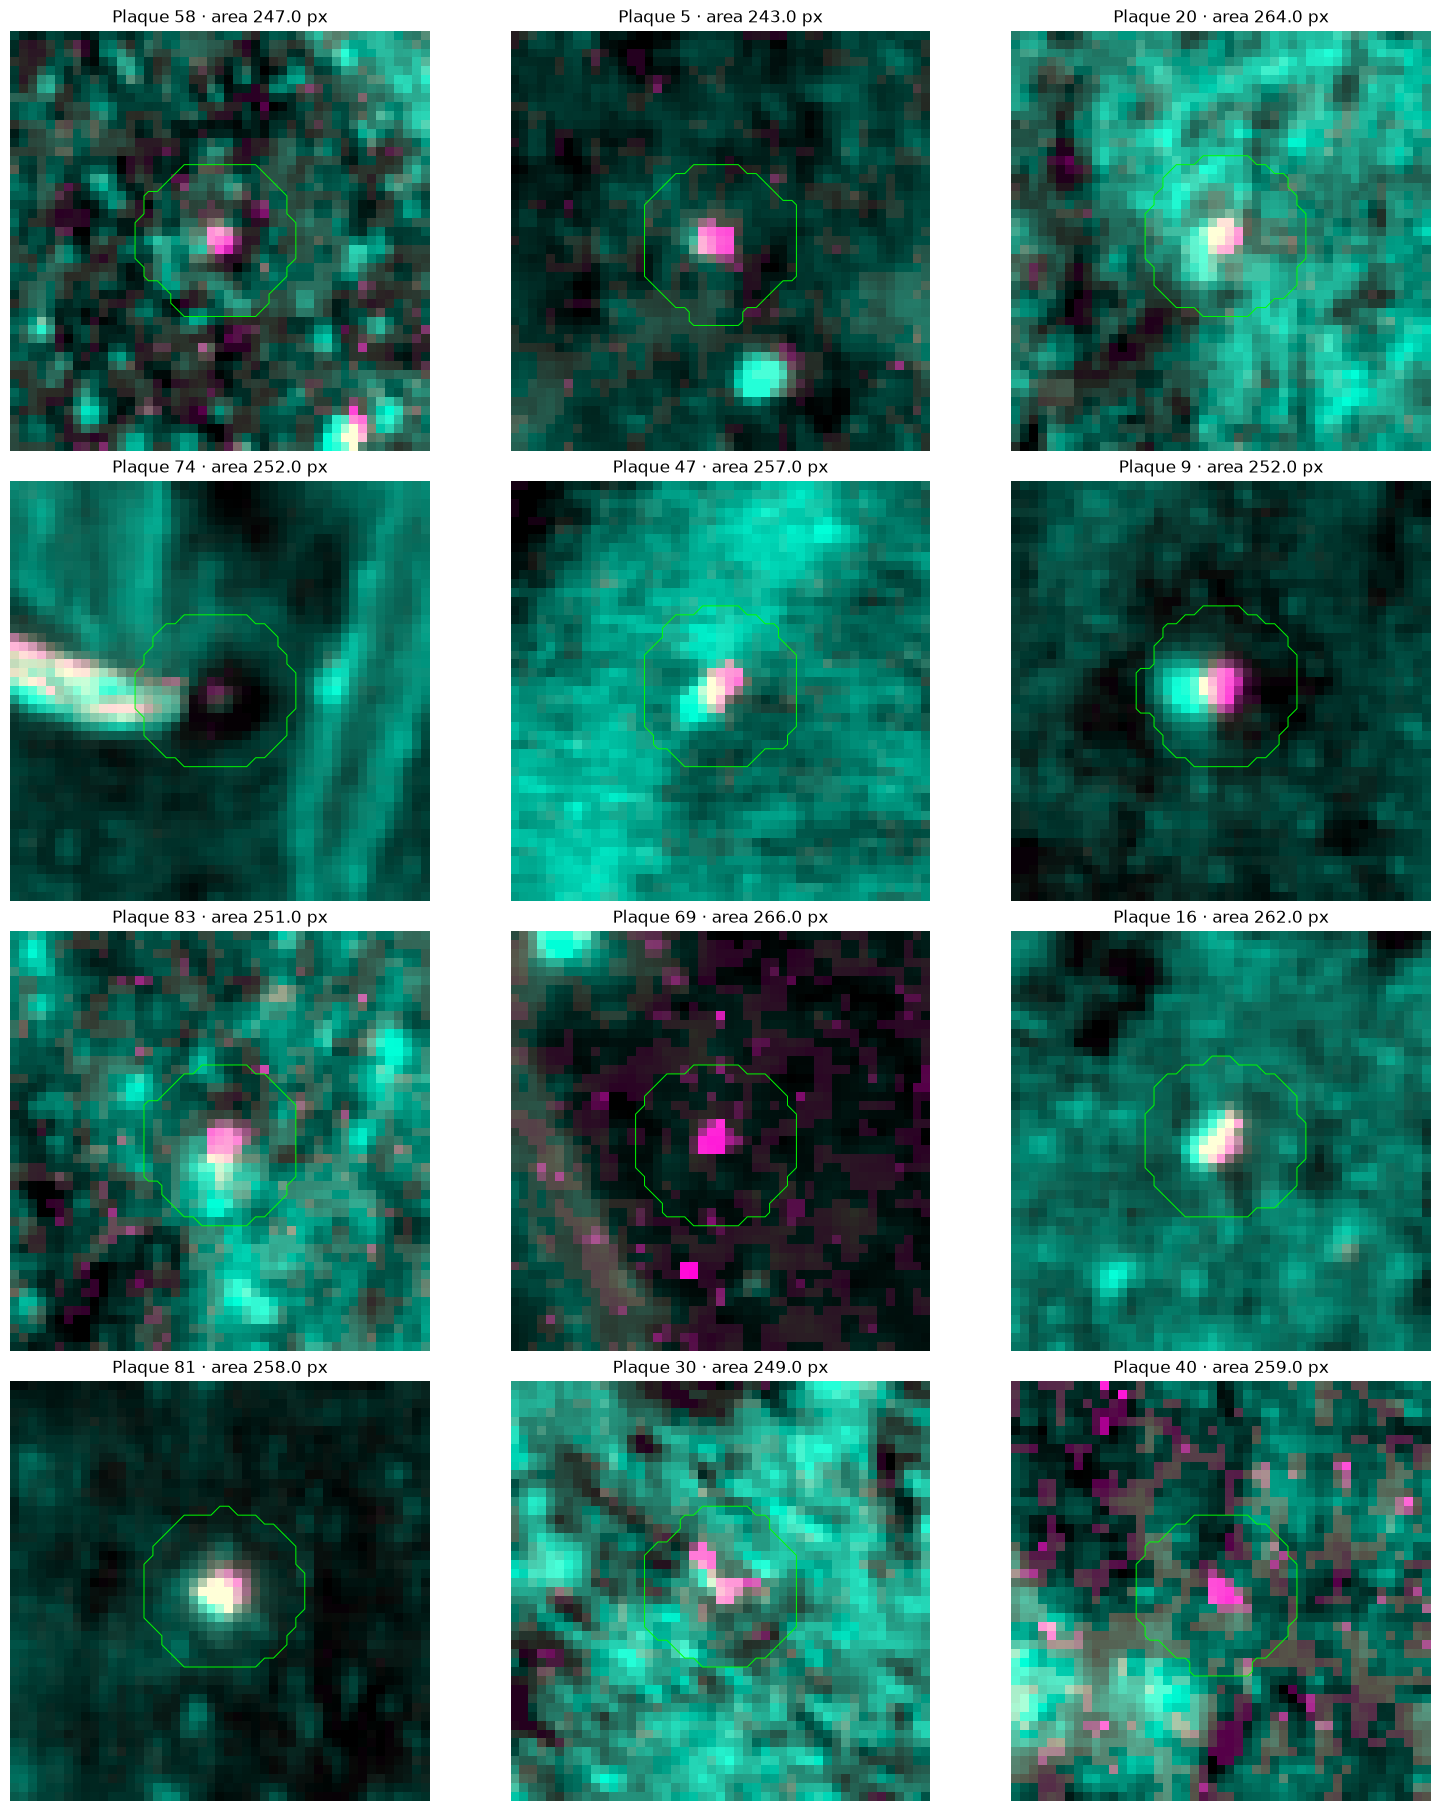

Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures\06_plaque_zooms.png


In [10]:
# Reproducible sampling from final connected plaque regions.
regions = list(measure.regionprops(measure.label(mask_after > 0)))
rng = np.random.default_rng(PLAQUE_ZOOM_SEED)

if PLAQUE_ZOOM_SELECTION == "largest":
    regions.sort(key=lambda r: r.area, reverse=True)
elif PLAQUE_ZOOM_SELECTION == "random":
    rng.shuffle(regions)
elif PLAQUE_ZOOM_SELECTION == "mixed":
    n_largest = min(len(regions), PLAQUE_ZOOM_COUNT // 2)
    largest = sorted(regions, key=lambda r: r.area, reverse=True)[:n_largest]
    remaining = [r for r in regions if r.label not in {a.label for a in largest}]
    rng.shuffle(remaining)
    regions = largest + remaining
else:
    raise ValueError("PLAQUE_ZOOM_SELECTION must be largest, random, or mixed")

selected = regions[:PLAQUE_ZOOM_COUNT]
print(f"Plaque components: {len(regions)}; selected for display: {len(selected)}")

if selected:
    # Radius uses MIR pixel spacing in mm; zoom is for visual QC only.
    radius_px = max(8, int(round(2.5 * PLAQUE_RADIUS_UM / 1000 / min(images["MIR"].GetSpacing()[:2]))))
    cols = 3
    rows = math.ceil(len(selected) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4.5 * rows), squeeze=False, constrained_layout=True)
    for ax, reg in zip(axes.flat, selected):
        cy, cx = (int(round(v)) for v in reg.centroid)
        y0, y1 = max(0, cy - radius_px), min(mir_array.shape[0], cy + radius_px + 1)
        x0, x1 = max(0, cx - radius_px), min(mir_array.shape[1], cx + radius_px + 1)
        ax.imshow(rgb_overlay(mir_array[y0:y1, x0:x1], if_after[y0:y1, x0:x1], limit=1000))
        show_mask_edges(ax, mask_after[y0:y1, x0:x1], limit=1000)
        ax.set_title(f"Plaque {reg.label} · area {reg.area} px")
        ax.axis("off")
    for ax in list(axes.flat)[len(selected):]:
        ax.axis("off")
    plaque_file = save_show(fig, "06_plaque_zooms.png")
else:
    print("No positive plaque components were found in the final mask.")


## 10. Display package-generated QC figures

S1_N2_qc_alignment_MIR_IF_QC.png


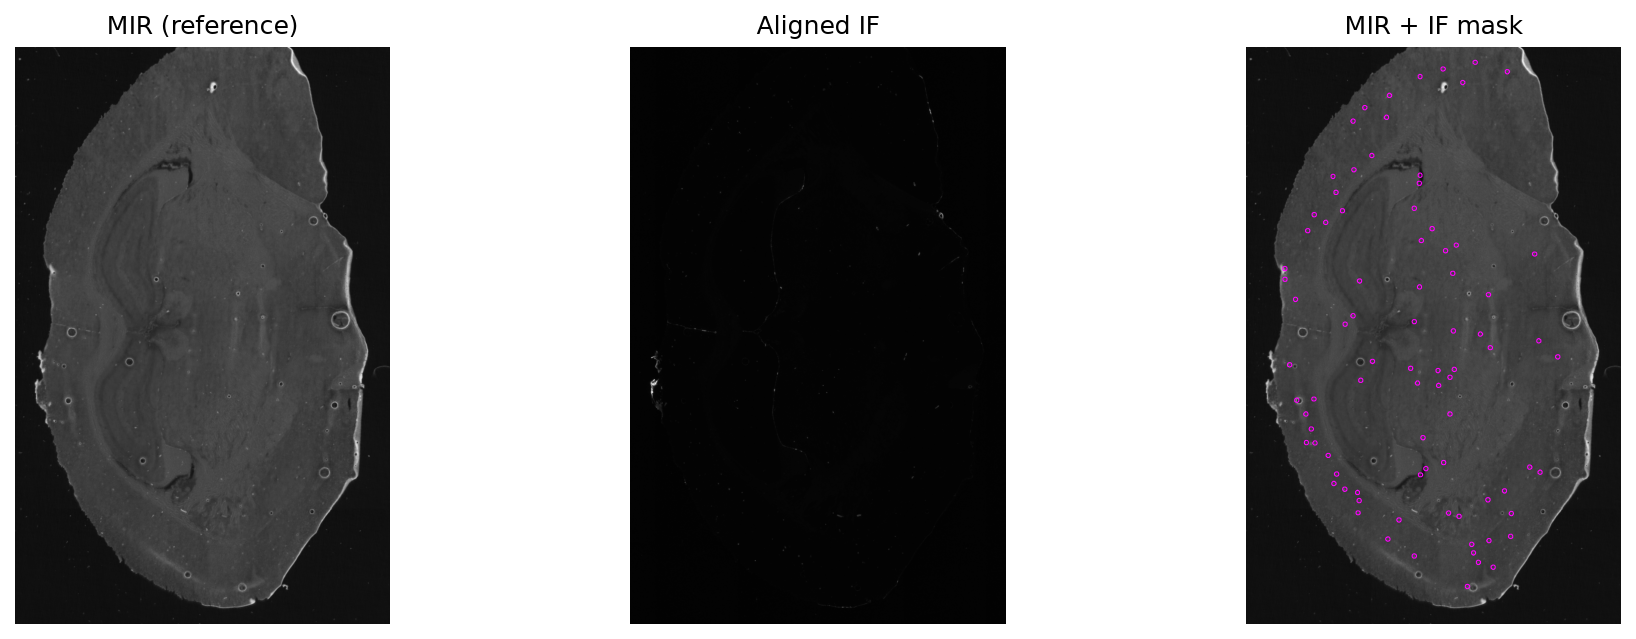

S1_N2_qc_alignment_plaque_zooms.png


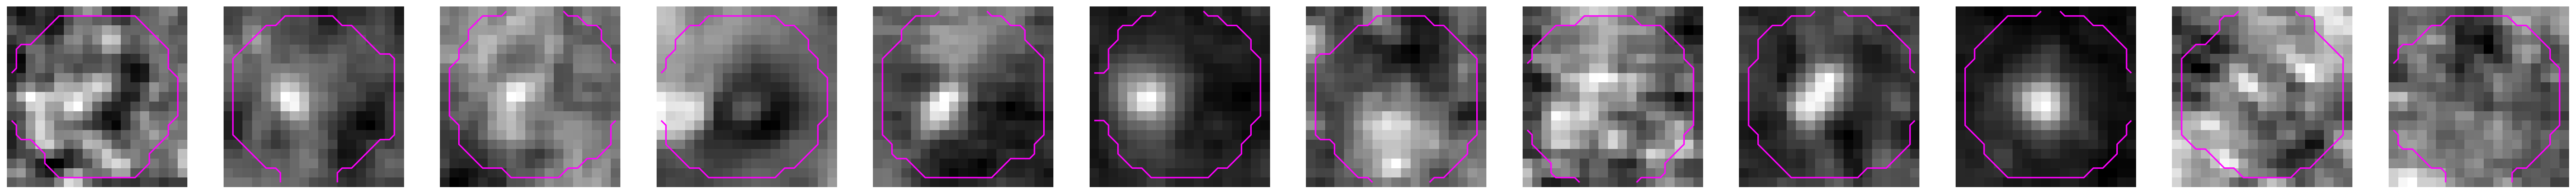

Saved QC JSON: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\S1_N2_qc_alignment_MIR_IF_alignment_QC_summary.json
Final IF NRRD : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\S1_N2_qc_alignment_IF_refined_on_MIR_grid.nrrd
Final mask NRRD: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\S1_N2_qc_alignment_IF_mask_refined_on_MIR_grid.nrrd
Tutorial PNGs : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_qc_alignment\qc_figures


In [11]:
# These images are created by qc.Run(), not by the notebook.
qc_figures = [Path(path) for path in qc.GetSavedFigures()]
for path in qc_figures:
    if path.is_file():
        print(path.name)
        display(NotebookImage(filename=str(path)))
    else:
        print("Missing QC figure:", path)

print("Saved QC JSON:", qc.summary_json_path)
print("Final IF NRRD :", qc.if_on_mir_path)
print("Final mask NRRD:", qc.mask_on_mir_path)
print("Tutorial PNGs :", figures_dir)


## 11. Inspect the saved result and SpatialData

In [12]:
# Read the package's saved summary and confirm the output files.
saved_summary = json.loads(qc.summary_json_path.read_text(encoding="utf-8"))
print("Saved status:", saved_summary.get("status"))
for path in [qc.if_on_mir_path, qc.mask_on_mir_path, qc.summary_json_path]:
    assert path.exists(), f"Missing QC output: {path}"
    print("OK:", path.name)

sdata = qc.GetSpatialData()
print("SpatialData image elements:", list(sdata.images))
print("SpatialData label elements:", list(sdata.labels))


Saved status: REVIEW
OK: S1_N2_qc_alignment_IF_refined_on_MIR_grid.nrrd
OK: S1_N2_qc_alignment_IF_mask_refined_on_MIR_grid.nrrd
OK: S1_N2_qc_alignment_MIR_IF_alignment_QC_summary.json
SpatialData image elements: ['brightfield', 'mir_aligned', 'if_aligned']
SpatialData label elements: ['mask_aligned']
